# 00 · Getting started with SPARTA

**What you'll learn**

- what SPARTA does, and which object does what
- how to load a directory of archive spectra with `Observations`
- what a `Spectrum` holds: orders, wavelengths, flux, time, barycentric correction
- what `sparta.instruments` knows about each spectrograph
- SPARTA's unit conventions

## What SPARTA is

SPARTA (**SP**ectroscopic v**AR**iabili**T**y **A**nalysis) analyses a *spectroscopic time
series*: many spectra of one star, taken at different times. It measures radial velocities
(RVs) and searches the spectra, or the RVs, for periodic signals.

| Task | SPARTA object | Notebook |
|---|---|---|
| read archive spectra (or simulate them) | `Observations`, `sparta.instruments` | 00 |
| RV of a single-lined star (CCF) | `CCF1d` (engine: `unicor`) | 02 |
| RVs of both stars of a double-lined binary | `CCF2d` (engine: `todcor`) | 03 |
| a template built from the observations | `TIRAVEL` | 04 |
| periodograms: GLS, PDC, USuRPER | `PeriodicityDetector` | 05 |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sparta
from sparta import Observations, instruments

plt.rcParams.update({
    "figure.figsize": (8, 3.2), "figure.dpi": 100, "figure.constrained_layout.use": True,
    "font.size": 11, "axes.titlesize": 11, "legend.fontsize": 9, "legend.frameon": False,
})
print("SPARTA", sparta.__version__)
print("public objects:", ", ".join(sparta.__all__))

SPARTA 0.3.0
public objects: Spectrum, Template, Observations, TimeSeries, CCF1d, CCF2d, TIRAVEL, PeriodicityDetector, instruments


## Load the bundled data

Two real data sets ship in `examples/data/`:

- `TOI677/`: 12 spectra from **NRES** (the Las Cumbres Observatory echelle network), all 67 echelle orders each;
- `TOI193/`: 32 spectra from **HARPS** (ESO archive 1-D products, one merged spectrum each).

Every archive stores wavelengths, flux, times and the barycentric correction differently.
The `survey` key tells `Observations` which loader to use. HARPS 1-D products cover the whole
optical range in one array, so we also choose a wavelength window (`min_wv`, `max_wv`, in Å);
multi-order products such as NRES ignore it.

In [2]:
nres = Observations(survey="NRES", target_visits_lib="data/TOI677/")
harps = Observations(survey="HARPS", target_visits_lib="data/TOI193/", min_wv=4990, max_wv=5090)

for name, obs in [("NRES / TOI-677", nres), ("HARPS / TOI-193", harps)]:
    print(f"{name}: {obs.sample_size} epochs, {len(obs.spec_list[0].wv)} order(s), "
          f"spanning {np.ptp(obs.time_list):.1f} days")
    print(f"    time system: {obs.time_system!r}, wavelength frame: {obs.wavelength_frame!r}")

NRES / TOI-677: 12 epochs, 67 order(s), spanning 30.9 days
    time system: 'BJD-TDB', wavelength frame: None
HARPS / TOI-193: 32 epochs, 1 order(s), spanning 54.1 days
    time system: 'BJD (HARPS DRS; scale unverified)', wavelength frame: 'air'


`wavelength_frame` is `'air'` for HARPS and `None` for this NRES product: its pipeline does not
document whether its wavelengths are in air or in vacuum (notebook 01 explains why it matters).

## What is inside: a `Spectrum`

`obs.spec_list` holds one `Spectrum` per epoch. A `Spectrum` keeps one wavelength array and one
flux array **per echelle order**, in the lists `wv` and `sp`.

In [3]:
spec = nres.spec_list[0]
print(f"{spec.n_ord} orders, {len(spec.wv[0])} pixels in order 0")
for i in (0, 33, 66):
    print(f"  order {i:2d}: {spec.wv[i][0]:7.1f} - {spec.wv[i][-1]:7.1f} Å")

67 orders, 4096 pixels in order 0
  order  0:  8877.1 -  9055.1 Å
  order 33:  5425.9 -  5536.1 Å
  order 66:  3894.3 -  3977.1 Å


(NRES numbers its orders from red to blue.)

**Times.** `obs.time_list` counts days from `obs.first_time`, the integer day of the first visit,
so that small differences keep full floating-point precision. The epochs are in the order the
files were found on disk, not in time order.

In [4]:
print("first_time (BJD, integer day):", nres.first_time)
print("time_list (days):", np.round(nres.time_list[:4], 3), "...")

first_time (BJD, integer day): 2458624
time_list (days): [0.565 1.534 2.537 3.52 ] ...


**Barycentric correction.** The Earth moves around the Sun at up to 30 km/s, which shifts every
spectrum. NRES wavelengths are topocentric, so on loading `Observations` multiplies them by
$(1 + v_{\rm bc}/c)$. The correction is kept in `obs.bcv` (km/s), and each spectrum's own `bcv` is
set to 0 so it cannot be applied twice. HARPS archive spectra are already barycentric (`bcv = 0`).

In [5]:
print("NRES bcv (km/s):", np.round(nres.bcv[:4], 3), "...")
print("spectrum bcv after loading:", spec.bcv)
print("HARPS bcv (km/s):", harps.bcv[:4], "...")

NRES bcv (km/s): [-13.705 -13.785 -13.903 -13.99 ] ...
spectrum bcv after loading: 0.0 km / s
HARPS bcv (km/s): [0.0, 0.0, 0.0, 0.0] ...


## Look at a spectrum

These are the spectra as the archives deliver them, not normalised. In the NRES order, note
the unexposed margins at both ends (the pipeline pads each order with background-subtracted
detector, which reads zero plus noise), the noisier order edges and the narrow upward spikes
(cosmic-ray hits). Notebook 02 shows the preprocessing that deals with all three. The
three strong NRES lines are the Mg b triplet (5167, 5173 and 5184 Å).

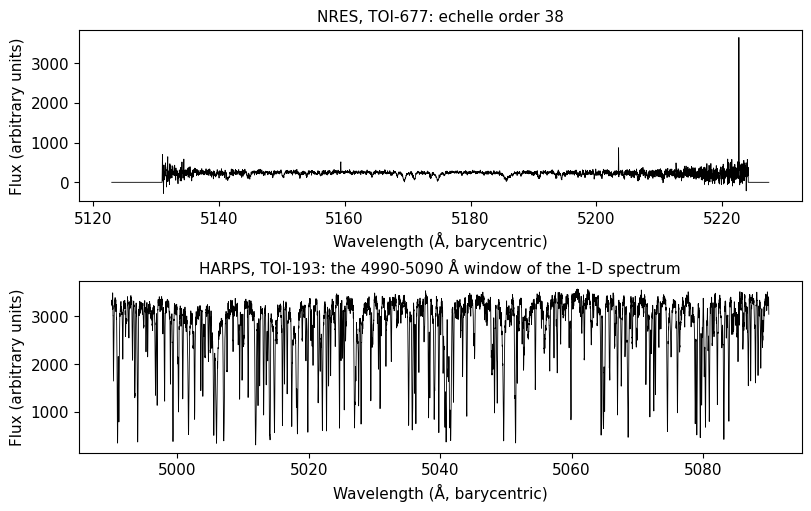

In [6]:
order = next(i for i, w in enumerate(spec.wv) if w[0] < 5175 < w[-1])
hspec = harps.spec_list[0]

fig, axs = plt.subplots(2, 1, figsize=(8, 5))
axs[0].plot(spec.wv[order], spec.sp[order], "k", lw=0.6)
axs[0].set_title(f"NRES, TOI-677: echelle order {order}")
axs[1].plot(hspec.wv[0], hspec.sp[0], "k", lw=0.6)
axs[1].set_title("HARPS, TOI-193: the 4990-5090 Å window of the 1-D spectrum")
for ax in axs:
    ax.set_xlabel("Wavelength (Å, barycentric)")
    ax.set_ylabel("Flux (arbitrary units)")
plt.show()

## What `sparta.instruments` knows

Each survey key maps to a `Product` (one archive data product) and its `Instrument`. They record
what the analysis needs to know: resolving power, native pixel size, wavelength frame, time
system, and starting-point analysis settings.

In [7]:
print("survey keys:", ", ".join(sorted(instruments.REGISTRY)))

survey keys: APOGEE, CORALIE, ELODIE, FEROS, FEROS-CERES, HARPS, HARPS-CERES, LAMOST, NRES, NRES-BANZAI, PEPSI, SIMULATED, SRG, TRES, UVES


In [8]:
for key in ("NRES", "HARPS"):
    product = instruments.get(key)
    inst = product.instrument
    rec = product.recommended
    fwhm = 299792.458 / inst.resolving_power              # km/s
    print(f"{key}: {product.description}")
    print(f"    R = {inst.resolving_power:,.0f}  ->  line-spread FWHM c/R = {fwhm:.2f} km/s")
    print(f"    native (detector) step = {inst.native_step_kms:.3f} km/s per pixel "
          f"({fwhm / inst.native_step_kms:.1f} pixels per FWHM)")
    print(f"    archive grid: {product.grid}; resampled by the archive: {product.resampled}")
    print(f"    wavelength frame: {product.wavelength_frame}, SPECSYS: {product.specsys}, "
          f"time: {product.time_system}")
    print(f"    recommended: dv = {rec.dv_kms} km/s, window = {rec.window_A}, "
          f"drop {len(rec.drop_orders)} orders")
    print(f"    recommended preprocess: {rec.preprocess}\n")

NRES: NRES commissioning (IDL) pipeline extracted spectrum, RLEVEL 91 ('*-e91.fits'): HDU2 SPECFLAT flux and HDU6 WAVESPEC wavelengths (nm), 67 orders x 4096 pixels.
    R = 53,000  ->  line-spread FWHM c/R = 5.66 km/s
    native (detector) step = 1.450 km/s per pixel (3.9 pixels per FWHM)
    archive grid: native echelle pixels; resampled by the archive: False
    wavelength frame: None, SPECSYS: TOPOCENT, time: BJD-TDB
    recommended: dv = 0.05 km/s, window = None, drop 27 orders
    recommended preprocess: {'n_trim': 100, 'clean_margins': True, 'remove_nans': True, 'delta': 0.5, 'cosmic_sigma': 3, 'filter_lowcut': 4, 'filter_highcut': 0.15, 'alpha': 0.3}

HARPS: ESO Phase-3 SDP 1-D spectrum (ADP.*.fits, HARPS DRS s1d): one-row binary table in HDU1 with WAVE / FLUX / ERR columns.
    R = 120,000  ->  line-spread FWHM c/R = 2.50 km/s
    native (detector) step = 0.609 km/s per pixel (4.1 pixels per FWHM)
    archive grid: linear, 0.01 Angstrom per pixel (SPEC_BIN = 0.001 nm); resampl

A few things to notice:

- **Resolving power** sets the narrowest line width, $c/R$: 5.7 km/s for NRES, 2.5 km/s for HARPS.
- The **native step** is the detector pixel in velocity. The HARPS archive spectrum is
  *resampled* onto a 0.01 Å grid, finer than the detector in the red; SPARTA keeps the detector
  step so it does not count the extra samples as information (notebook 01).
- The **recommended settings** are starting points that worked on these data sets, not
  instrument documentation.
- The `SIMULATED` key builds synthetic spectra "as if" from a real product, with a known truth.
  Notebooks 02-06 use it.

`docs/instruments.md` lists every product.

## Units

Plain numbers in SPARTA carry these units:

| Quantity | Unit |
|---|---|
| wavelength | Å (the frame, air or vacuum, is stated per product) |
| velocity, RV, step `dv` | km/s |
| time | days (BJD for real data; `time_list` relative to `first_time`) |
| periodogram frequency | 1/day |

## Summary / next

- `Observations(survey=..., target_visits_lib=...)` loads a directory of spectra and applies the
  barycentric correction.
- A `Spectrum` holds per-order lists `wv` (Å) and `sp`; `obs.time_list` is in days.
- `sparta.instruments.get(key)` gives the resolving power, native step, frames and recommended
  settings.

**Next:** `01_spectra_and_log_lambda.ipynb`: why cross-correlation needs a log-λ grid.